NIH CHESTX-RAY14 DATASET
Dataset size       : 86,511
Image size         : 224 x 224
Image channels     : 1 (Grayscale)
Metadata dimension : 16
Target             : Patient Age
Batch size         : 32

Age statistics:
mean        46.605622
std         16.661603
min          1.000000
max         95.000000
count    86511.000000

Finding labels:
  [00] Atelectasis
  [01] Cardiomegaly
  [02] Consolidation
  [03] Edema
  [04] Effusion
  [05] Emphysema
  [06] Fibrosis
  [07] Hernia
  [08] Infiltration
  [09] Mass
  [10] Nodule
  [11] Pleural_Thickening
  [12] Pneumonia
  [13] Pneumothorax

SAMPLE 1 | Dataset index: 83810
Image       : 00028764_004.png
Age         : 24
Sex         : F (1)
View        : PA (0)
Findings    : Effusion, Infiltration, Pneumonia
Metadata    : [1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0, 0.0]
Image shape : (1, 224, 224)

SAMPLE 2 | Dataset index: 14592
Image       : 00004680_003.png
Age         : 30
Sex         : M (0)
View        : AP 

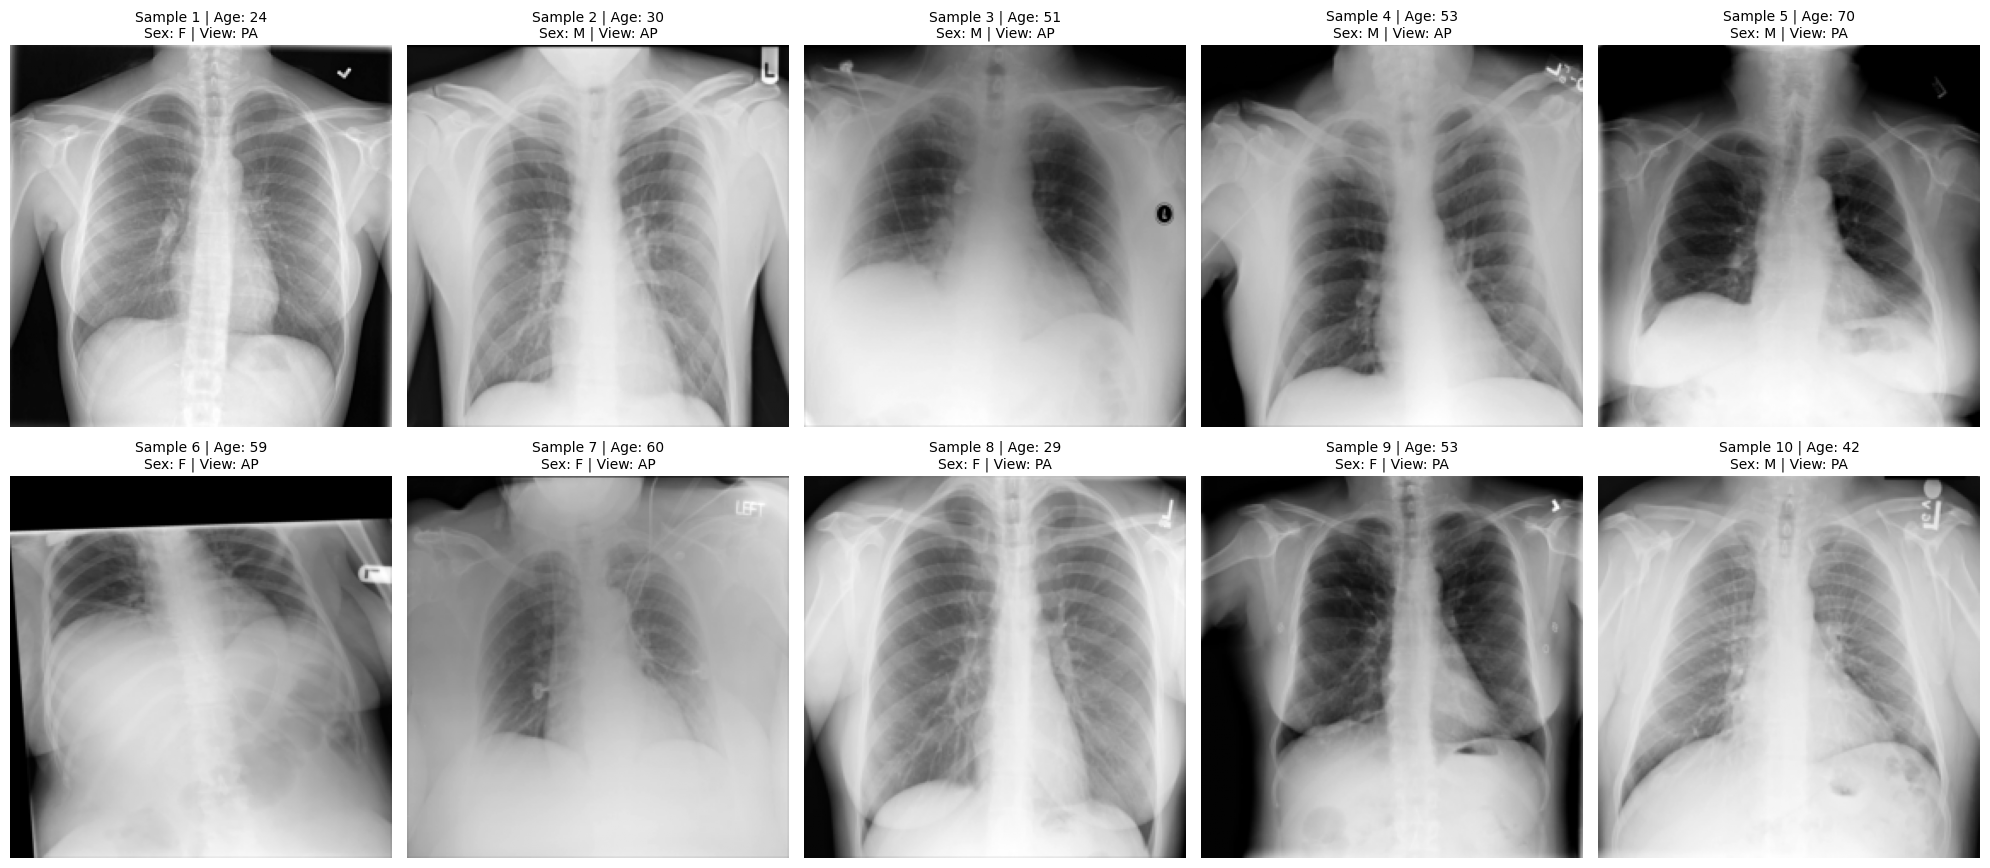

In [16]:

import os
import random
import matplotlib.pyplot as plt
import pandas as pd
import torch

from pathlib import Path
from torch.utils.data import DataLoader

# ============================================================
# 1. CONFIGURATION
# ============================================================
DATASET_ROOT = Path(r"D:\datasets\CXR8")

CSV_PATH = DATASET_ROOT / "Data_Entry_2017_v2020.csv"
IMAGES_ROOT = DATASET_ROOT
TRAIN_LIST = DATASET_ROOT / "train_val_list.txt"

IMAGE_SIZE = 224
NUM_SAMPLES = 10
BATCH_SIZE = 32

# ============================================================
# 2. IMPORT DATASET MODULE
# ============================================================
# Điều chỉnh import nếu dataset.py nằm trong package khác
from src.dataset import (
    ChestXrayAgeDataset,
    get_val_transforms,
    FINDING_LABELS
)

# ============================================================
# 3. LOAD DATASET
# ============================================================
dataset = ChestXrayAgeDataset(
    csv_path=str(CSV_PATH),
    images_root=str(IMAGES_ROOT),
    split_list_path=str(TRAIN_LIST),
    transform=get_val_transforms(image_size=IMAGE_SIZE),
    min_age=1,
    max_age=100
)

loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

# ============================================================
# 4. DATASET INFORMATION
# ============================================================
print("=" * 65)
print("NIH CHESTX-RAY14 DATASET")
print("=" * 65)

print(f"Dataset size       : {len(dataset):,}")
print(f"Image size         : {IMAGE_SIZE} x {IMAGE_SIZE}")
print(f"Image channels     : 1 (Grayscale)")
print(f"Metadata dimension : 16")
print(f"Target             : Patient Age")
print(f"Batch size         : {BATCH_SIZE}")

print("\nAge statistics:")
print(pd.Series(dataset.get_age_stats()).to_string())

print("\nFinding labels:")
for i, label in enumerate(FINDING_LABELS):
    print(f"  [{i:02d}] {label}")

# ============================================================
# 5. RANDOM 10 SAMPLES
# ============================================================
random.seed(42)
indices = random.sample(
    range(len(dataset)),
    min(NUM_SAMPLES, len(dataset))
)

fig, axes = plt.subplots(2, 5, figsize=(20, 9))
axes = axes.flatten()

for plot_idx, data_idx in enumerate(indices):

    image, metadata, target = dataset[data_idx]

    # Undo normalization for visualization
    image_show = image.squeeze(0).cpu().numpy()
    image_show = image_show * 0.2520 + 0.5006
    image_show = image_show.clip(0, 1)

    # Decode metadata
    sex_enc = int(metadata[0].item())
    view_enc = int(metadata[1].item())

    sex = "F" if sex_enc == 1 else "M"
    view = "AP" if view_enc == 1 else "PA"

    finding_values = metadata[2:].cpu().numpy()

    active_findings = [
        FINDING_LABELS[i]
        for i, value in enumerate(finding_values)
        if value == 1
    ]

    if not active_findings:
        active_findings = ["No Finding"]

    age = target.item()

    # Display image
    axes[plot_idx].imshow(image_show, cmap="gray")
    axes[plot_idx].set_title(
        f"Sample {plot_idx + 1} | Age: {age:.0f}\n"
        f"Sex: {sex} | View: {view}",
        fontsize=10
    )
    axes[plot_idx].axis("off")

    # Print metadata
    print("\n" + "=" * 55)
    print(f"SAMPLE {plot_idx + 1} | Dataset index: {data_idx}")
    print("=" * 55)
    print(f"Image       : {dataset.df.iloc[data_idx]['Image Index']}")
    print(f"Age         : {age:.0f}")
    print(f"Sex         : {sex} ({sex_enc})")
    print(f"View        : {view} ({view_enc})")
    print(f"Findings    : {', '.join(active_findings)}")
    print(f"Metadata    : {metadata.tolist()}")
    print(f"Image shape : {tuple(image.shape)}")

plt.tight_layout()
plt.show()
